In [1]:
import sys
REPO = r"C:\Users\saqib\OneDrive\Desktop\Sem 5\AI\Project\telecom-value-based-retention"
sys.path.append(REPO)

In [2]:
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from src.utils.config import SEED, PROCESSED_DATA_DIR

# Loading Data

In [3]:

sys.path.append("..")

train = pd.read_csv(PROCESSED_DATA_DIR / "train_encoded.csv")
val   = pd.read_csv(PROCESSED_DATA_DIR / "val_encoded.csv")
test  = pd.read_csv(PROCESSED_DATA_DIR / "test_encoded.csv")
print(train.shape, val.shape, test.shape)

(4930, 85) (1056, 85) (1057, 85)


# Prep X and Y

In [4]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 85 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 4930 non-null   float64
 1   Number of Dependents                4930 non-null   float64
 2   Latitude                            4930 non-null   float64
 3   Longitude                           4930 non-null   float64
 4   Number of Referrals                 4930 non-null   float64
 5   Tenure in Months                    4930 non-null   float64
 6   Avg Monthly Long Distance Charges   4930 non-null   float64
 7   Avg Monthly GB Download             4930 non-null   float64
 8   Monthly Charge                      4930 non-null   float64
 9   Total Charges                       4930 non-null   float64
 10  Total Refunds                       4930 non-null   float64
 11  Total Extra Data Charges            4930 no

In [5]:
X_train = train.drop(columns = ['Churn','City','Zip Code'])

In [6]:
y_train = train["Churn"]

In [7]:
X_val = val.drop(columns = ['Churn','City','Zip Code'])
y_val = val["Churn"]

In [8]:
X_test = test.drop(columns=["Churn", "City", "Zip Code"])
y_test = test["Churn"]

In [9]:
print("X shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Churn rate:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos
print(f"churners: {pos}, non-churners: {neg}, scale_pos_weight: {spw:.2f}")

X shapes: (4930, 82) (1056, 82) (1057, 82)
Churn rate: 0.265 0.265 0.266
churners: 1308, non-churners: 3622, scale_pos_weight: 2.77


In [10]:
def clean_names(df):
    return df.rename(columns=lambda c: c.replace("<", "lt_").replace("[", "(").replace("]", ")"))

X_train, X_val, X_test = clean_names(X_train), clean_names(X_val), clean_names(X_test)
print([c for c in X_train.columns if "Age_Band" in c])

['Age_Band_30-50', 'Age_Band_50+', 'Age_Band_lt_30']


# Models

## Logistic Regression

In [11]:
print(SEED)

42


In [12]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

In [13]:
from tqdm.auto import tqdm

with tqdm(total=1, desc="Training Logistic Regression") as bar:
    lr.fit(X_train, y_train)
    bar.update(1)

Training Logistic Regression:   0%|          | 0/1 [00:00<?, ?it/s]

In [14]:
val_proba = lr.predict_proba(X_val)[:, 1]
print(val_proba[:10].round(3))

[0.013 0.699 0.002 0.061 0.948 0.936 0.023 0.709 0.558 0.015]


In [15]:
threshold = 0.5
val_pred = (val_proba >= threshold).astype(int)
print("Predicted churners:", val_pred.sum(), "out of", len(val_pred))
print("Actual churners:   ", y_val.sum(),"out of", len(y_val))

Predicted churners: 405 out of 1056
Actual churners:    280 out of 1056


In [16]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score

print("ROC-AUC  :", round(roc_auc_score(y_val, val_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, val_proba), 3))
print("Precision:", round(precision_score(y_val, val_pred), 3))
print("Recall   :", round(recall_score(y_val, val_pred), 3))
print("F1       :", round(f1_score(y_val, val_pred), 3))

ROC-AUC  : 0.886
PR-AUC   : 0.736
Precision: 0.568
Recall   : 0.821
F1       : 0.672


In [17]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_val, val_pred))

[[601 175]
 [ 50 230]]


## Random Forest

In [18]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=SEED
)

In [19]:
rf.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', min_samples_leaf=5,
                       n_estimators=300, random_state=42)

In [20]:
rf_proba = rf.predict_proba(X_val)[:, 1]
print(rf_proba[:10].round(3))

[0.052 0.567 0.008 0.11  0.84  0.74  0.014 0.434 0.382 0.16 ]


In [21]:
threshold = 0.5
rf_pred = (rf_proba >= threshold).astype(int)
print("Predicted churners:", rf_pred.sum(), "out of", len(rf_pred))
print("Actual churners:   ", y_val.sum())

Predicted churners: 331 out of 1056
Actual churners:    280


In [22]:
print("ROC-AUC  :", round(roc_auc_score(y_val, rf_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, rf_proba), 3))
print("Precision:", round(precision_score(y_val, rf_pred), 3))
print("Recall   :", round(recall_score(y_val, rf_pred), 3))
print("F1       :", round(f1_score(y_val, rf_pred), 3))

ROC-AUC  : 0.895
PR-AUC   : 0.753
Precision: 0.634
Recall   : 0.75
F1       : 0.687


In [23]:
print(confusion_matrix(y_val, rf_pred))

[[655 121]
 [ 70 210]]


## XG Boost

In [24]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [25]:
from xgboost import XGBClassifier
from tqdm.auto import tqdm
from xgboost.callback import TrainingCallback

class TqdmProgress(TrainingCallback):
    def __init__(self, total):
        self.bar = tqdm(total=total, desc="Training XGBoost")
    def after_iteration(self, model, epoch, evals_log):
        self.bar.update(1)
        return False          # False means "keep training"
    def after_training(self, model):
        self.bar.close()
        return model

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=SEED,
    callbacks=[TqdmProgress(300)]
)
xgb.fit(X_train, y_train)

Training XGBoost:   0%|          | 0/300 [00:00<?, ?it/s]

XGBClassifier(base_score=None, booster=None,
              callbacks=[<__main__.TqdmProgress object at 0x000001E6BE4E7A10>],
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [26]:
xgb_proba = xgb.predict_proba(X_val)[:, 1]
print(xgb_proba[:10].round(3))

[0.019 0.882 0.003 0.01  0.88  0.959 0.012 0.739 0.314 0.063]


In [27]:
threshold = 0.5
xgb_pred = (xgb_proba >= threshold).astype(int)
print("Predicted churners:", xgb_pred.sum(), "out of", len(xgb_pred))
print("Actual churners:   ", y_val.sum())

Predicted churners: 372 out of 1056
Actual churners:    280


In [28]:
print("ROC-AUC  :", round(roc_auc_score(y_val, xgb_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, xgb_proba), 3))
print("Precision:", round(precision_score(y_val, xgb_pred), 3))
print("Recall   :", round(recall_score(y_val, xgb_pred), 3))
print("F1       :", round(f1_score(y_val, xgb_pred), 3))

ROC-AUC  : 0.898
PR-AUC   : 0.769
Precision: 0.602
Recall   : 0.8
F1       : 0.687


In [29]:
print(confusion_matrix(y_val, xgb_pred))

[[628 148]
 [ 56 224]]


# Model Comparison

In [30]:
lr_proba, lr_pred = val_proba, val_pred

In [31]:
probas = {"Logistic Regression": lr_proba, "Random Forest": rf_proba, "XGBoost": xgb_proba}
preds  = {"Logistic Regression": lr_pred,  "Random Forest": rf_pred,  "XGBoost": xgb_pred}

rows = []
for name in probas:
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_val, probas[name]),
        "PR-AUC": average_precision_score(y_val, probas[name]),
        "Precision": precision_score(y_val, preds[name]),
        "Recall": recall_score(y_val, preds[name]),
        "F1": f1_score(y_val, preds[name]),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,ROC-AUC,PR-AUC,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.886,0.736,0.568,0.821,0.672
Random Forest,0.895,0.753,0.634,0.750,0.687
XGBoost,0.898,0.769,0.602,0.800,0.687


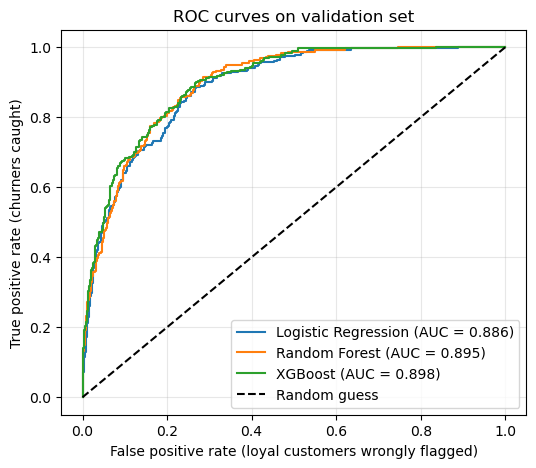

In [32]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_val, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate (loyal customers wrongly flagged)")
plt.ylabel("True positive rate (churners caught)")
plt.title("ROC curves on validation set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

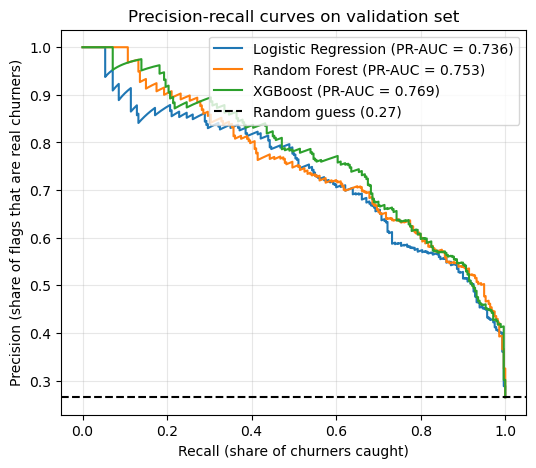

In [33]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(6, 5))
for name, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_val, p)
    plt.plot(rec, prec, label=f"{name} (PR-AUC = {average_precision_score(y_val, p):.3f})")
plt.axhline(y_val.mean(), color="k", linestyle="--", label=f"Random guess ({y_val.mean():.2f})")
plt.xlabel("Recall (share of churners caught)")
plt.ylabel("Precision (share of flags that are real churners)")
plt.title("Precision-recall curves on validation set")
plt.legend(loc = "upper right")
plt.grid(alpha=0.3)
plt.show()

# Final Testing on test dataset

In [34]:
xgb_test_proba = xgb.predict_proba(X_test)[:, 1]
print(xgb_test_proba[:10].round(3))

[0.876 0.022 0.569 0.162 0.008 0.124 0.787 0.27  0.027 0.94 ]


In [35]:
threshold = 0.5
xgb_test_pred = (xgb_test_proba >= threshold).astype(int)
print("Predicted churners:", xgb_test_pred.sum(), "out of", len(xgb_test_pred))
print("Actual churners:   ", y_test.sum())

Predicted churners: 389 out of 1057
Actual churners:    281


In [36]:
threshold = 0.5
xgb_test_pred = (xgb_test_proba >= threshold).astype(int)
print("Predicted churners:", xgb_test_pred.sum(), "out of", len(xgb_test_pred))
print("Actual churners:   ", y_test.sum())

Predicted churners: 389 out of 1057
Actual churners:    281


In [37]:
print(confusion_matrix(y_test, xgb_test_pred))

[[622 154]
 [ 46 235]]


In [38]:
compare = pd.DataFrame({
    "Validation": [roc_auc_score(y_val, xgb_proba), average_precision_score(y_val, xgb_proba),
                   precision_score(y_val, xgb_pred), recall_score(y_val, xgb_pred), f1_score(y_val, xgb_pred)],
    "Test":       [roc_auc_score(y_test, xgb_test_proba), average_precision_score(y_test, xgb_test_proba),
                   precision_score(y_test, xgb_test_pred), recall_score(y_test, xgb_test_pred), f1_score(y_test, xgb_test_pred)],
}, index=["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]).round(3)
compare

,Validation,Test
ROC-AUC,0.898,0.908
PR-AUC,0.769,0.788
Precision,0.602,0.604
Recall,0.800,0.836
F1,0.687,0.701


In [39]:
from sklearn.metrics import accuracy_score

print("Validation accuracy:", round(accuracy_score(y_val, xgb_pred), 3))
print("Test accuracy:      ", round(accuracy_score(y_test, xgb_test_pred), 3))

Validation accuracy: 0.807
Test accuracy:       0.811


# Feature Importance

In [40]:
gain = xgb.get_booster().get_score(importance_type="gain")
importance = pd.Series(gain).sort_values(ascending=False)
importance = importance / importance.sum()

print("Features used by the model:", len(importance), "of", X_train.shape[1])
importance.head(15).round(4)

Features used by the model: 69 of 82


Contract_Month-to-Month       0.1851
Contract_Two Year             0.0760
Contract_One Year             0.0717
Premium Tech Support_No       0.0420
Online Security_No            0.0418
Number of Referrals           0.0325
Number of Dependents          0.0286
Has_Dependents                0.0272
Married_Yes                   0.0253
Payment Method_Credit Card    0.0209
Internet Type_Fiber Optic     0.0175
Streaming TV_Yes              0.0158
Paperless Billing_Yes         0.0157
Married_No                    0.0146
Streaming Movies_Yes          0.0133
dtype: float64

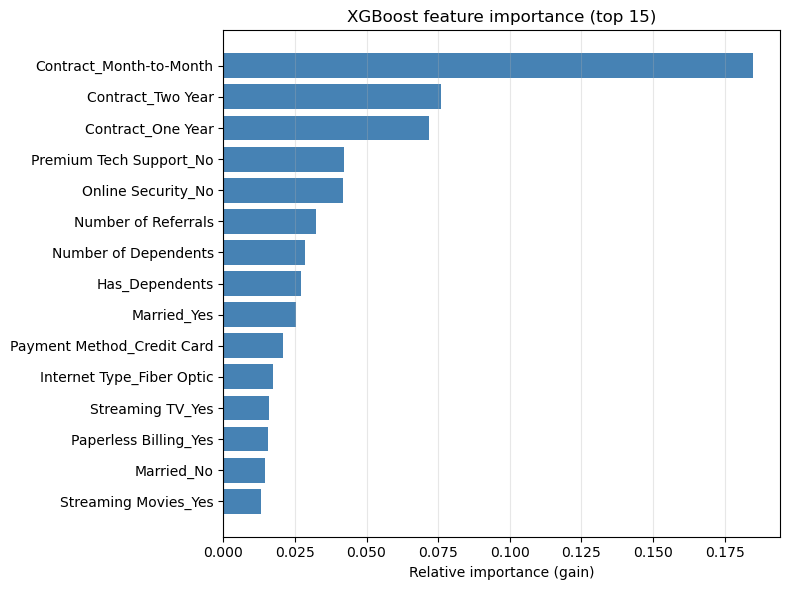

In [41]:
top = importance.head(15).sort_values()       # sorted so the biggest bar ends up on top

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color="steelblue")
plt.xlabel("Relative importance (gain)")
plt.title("XGBoost feature importance (top 15)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
parents = ["Gender", "Married", "Offer", "Phone Service", "Multiple Lines", "Internet Service",
           "Internet Type", "Online Security", "Online Backup", "Device Protection Plan",
           "Premium Tech Support", "Streaming TV", "Streaming Movies", "Streaming Music",
           "Unlimited Data", "Contract", "Paperless Billing", "Payment Method",
           "Age_Band", "Tenure_Group"]

def parent_of(col):
    for p in parents:
        if col.startswith(p + "_"):
            return p
    return col                                 # numeric features keep their own name

grouped = importance.groupby(parent_of).sum().sort_values(ascending=False)
grouped.head(12).round(4)

Contract                0.3328
Premium Tech Support    0.0490
Online Security         0.0483
Married                 0.0399
Offer                   0.0381
Payment Method          0.0338
Number of Referrals     0.0325
Internet Type           0.0290
Number of Dependents    0.0286
Paperless Billing       0.0276
Has_Dependents          0.0272
Tenure_Group            0.0233
dtype: float64